# Modélisation 

## Import des modules et lecture de data_clean.parquet

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 

#Selection
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV, 
    cross_validate,
)
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error 
from sklearn.inspection import permutation_importance

#Preprocess
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler

#Modèles
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor    #ajout jb

# Ajouts d'imports (jb) 
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    MaxAbsScaler,
    RobustScaler,
    QuantileTransformer,
    PowerTransformer
)
from sklearn.metrics import mean_absolute_percentage_error
import time
from datetime import datetime
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.compose import TransformedTargetRegressor

from sklearn.model_selection import StratifiedKFold
import shap

In [2]:
df_model = pd.read_parquet("data_clean.parquet")

## Feature Engineering

A réaliser : Enrichir le jeu de données actuel avec de nouvelles features issues de celles existantes. 

En règle générale : On utilise la méthode .apply() de Pandas pour créer une nouvelle colonne à partir d'une colonne existante. N'hésitez pas à regarder les exemples dans les chapitres de cours donnés en ressource

### Creation des Features Energy_ElecRatio, Energy_GasRatio et Energy_SteamRatio (Demande Mentor/Mohammed)

In [3]:
# Calcul du total kBTU
sum_conso = (
    df_model['Electricity(kBtu)'] + 
    df_model['NaturalGas(kBtu)'] + 
    df_model['SteamUse(kBtu)']
)
# Création des ratios
df_model['Energy_ElecRatio'] = df_model['Electricity(kBtu)'] /  sum_conso     #df_model['SiteEnergyUse(kBtu)']
df_model['Energy_GasRatio'] = df_model['NaturalGas(kBtu)'] / sum_conso        #df_model['SiteEnergyUse(kBtu)']
df_model['Energy_SteamRatio'] = df_model['SteamUse(kBtu)'] / sum_conso        #df_model['SiteEnergyUse(kBtu)']  



### Creation des Features Has_Electricity, Has_Gas et Has_Steam (Consignes Projet)

In [4]:
df_model['Has_Electricity'] = (df_model['Electricity(kBtu)'] > 0).astype(int)
df_model['Has_Gas']         = (df_model['NaturalGas(kBtu)'] > 0).astype(int)
df_model['Has_Steam']       = (df_model['SteamUse(kBtu)'] > 0).astype(int)

### Creation des Features de Ratio Parking & Building (sans parking) => Struct_BuildingRatio et Struct_ParkingRatio

In [5]:
# Ratios structurels (Physique du bâtiment)
df_model['Struct_BuildingRatio'] = df_model['PropertyGFABuilding(s)'] / df_model['PropertyGFATotal']
df_model['Struct_ParkingRatio'] = df_model['PropertyGFAParking'] / df_model['PropertyGFATotal']

# Vérification la somme doit être égale à 1 pour chaque ligne
#(df_model['Struct_BuildingRatio'] + df_model['Struct_ParkingRatio']).describe()

### SecondLargestPropertyUseType & GFA clean nan

In [6]:
#df_model['SecondLargestPropertyUseType'] = df_model['SecondLargestPropertyUseType'].fillna(
#    df_model['ListOfAllPropertyUseTypes'].str.split(',').str[1].str.strip())       

df_model['SecondLargestPropertyUseType'] = df_model['SecondLargestPropertyUseType'].fillna('Unknown')

df_model['SecondLargestPropertyUseTypeGFA'] = df_model['SecondLargestPropertyUseTypeGFA'].fillna(0)

### ThirdLargestPropertyUseType & GFA clean nan

In [7]:
#df_model['ThirdLargestPropertyUseType'] = df_model['ThirdLargestPropertyUseType'].fillna(
#    df_model['ListOfAllPropertyUseTypes'].str.split(',').str[2].str.strip())
df_model['ThirdLargestPropertyUseType'] = df_model['ThirdLargestPropertyUseType'].fillna('Unknown')

df_model['ThirdLargestPropertyUseTypeGFA'] = df_model['ThirdLargestPropertyUseTypeGFA'].fillna(0)

### Creation des Features de Ratio d'usage => Usage_1_Ratio, Usage_2_Ratio et Usage_3_Ratio

In [8]:
df_model['TotUsage123'] = df_model['LargestPropertyUseTypeGFA'] + df_model['SecondLargestPropertyUseTypeGFA'] + df_model['ThirdLargestPropertyUseTypeGFA']

# Création des ratios d'usage
df_model['Usage_1_Ratio'] = df_model['LargestPropertyUseTypeGFA'] / df_model['TotUsage123']   #'PropertyGFATotal'
df_model['Usage_2_Ratio'] = df_model['SecondLargestPropertyUseTypeGFA'] / df_model['TotUsage123']
df_model['Usage_3_Ratio'] = df_model['ThirdLargestPropertyUseTypeGFA'] / df_model['TotUsage123']


In [9]:
df_model.describe().round(2)

,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),LargestPropertyUseTypeGFA,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,...,Energy_SteamRatio,Has_Electricity,Has_Gas,Has_Steam,Struct_BuildingRatio,Struct_ParkingRatio,TotUsage123,Usage_1_Ratio,Usage_2_Ratio,Usage_3_Ratio
count,1469.00,1469.00,1469.00,1469.00,1469.00,1469.00,1469.00,1469.00,1469.00,1469.00,...,1469.00,1469.0,1469.00,1469.00,1469.00,1469.00,1469.00,1469.00,1469.00,1469.00
mean,1963.16,1.07,4.28,114034.47,14414.15,99620.32,92244.10,19671.25,3064.50,41.18,...,0.02,1.0,0.71,0.07,0.93,0.07,114979.85,0.85,0.13,0.02
std,31.58,0.54,6.49,192860.05,44695.06,168623.72,157310.67,50339.80,14648.85,38.09,...,0.09,0.0,0.45,0.26,0.15,0.15,201475.25,0.19,0.16,0.06
min,1901.00,1.00,0.00,11285.00,0.00,3636.00,5656.00,0.00,0.00,0.00,...,0.00,1.0,0.00,0.00,0.10,0.00,8223.00,0.33,0.00,0.00
25%,1935.00,1.00,1.00,28800.00,0.00,27800.00,25021.00,0.00,0.00,0.00,...,0.00,1.0,0.00,0.00,1.00,0.00,28841.00,0.71,0.00,0.00
50%,1966.00,1.00,2.00,47963.00,0.00,45743.00,41920.00,0.00,0.00,41.00,...,0.00,1.0,1.00,0.00,1.00,0.00,48783.00,1.00,0.00,0.00
75%,1989.00,1.00,4.00,105100.00,0.00,94500.00,91281.00,13805.00,0.00,79.00,...,0.00,1.0,1.00,0.00,1.00,0.00,103566.00,1.00,0.25,0.00
max,2015.00,9.00,76.00,1952220.00,512608.00,1765970.00,1680937.00,441551.00,303910.00,100.00,...,0.70,1.0,1.00,1.00,1.00,0.90,2080885.00,1.00,0.50,0.33


### Creation de la feature PeriodBuilt from YearBuilt (PeriodBuilt = tranche de 10 ans)

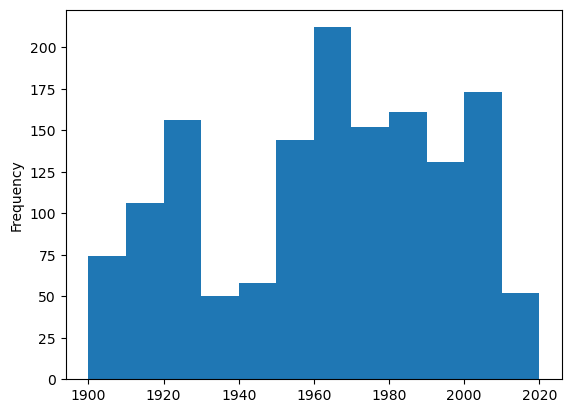

In [10]:
df_model['YearBuilt'].plot(kind='hist', bins=range(1900, 2021, 10))
plt.show()

In [11]:
df_model['PeriodBuilt'] = ((df_model['YearBuilt'] - 1900) // 10 + 1)

### Log_GFATotal et Log1p_SiteEUI, Log1p_SiteEUIWN, Log1p_SiteEnergyUse, Log1p_SiteEnergyUseWN, Log1p_GFATotal

In [12]:
df_model['Log1p_GFATotal'] = np.log1p(df_model['PropertyGFATotal'])

In [13]:
df_model['Log1p_SiteEUI'] = np.log1p(df_model['SiteEUI(kBtu/sf)'])

In [14]:
df_model['Log1p_SiteEUIWN'] = np.log1p(df_model['SiteEUIWN(kBtu/sf)'])

In [15]:
df_model['Log1p_SiteEnergyUseWN'] = np.log1p(df_model['SiteEnergyUseWN(kBtu)'])

In [16]:
df_model['Log1p_SiteEnergyUse'] = np.log1p(df_model['SiteEnergyUse(kBtu)'])

In [17]:
df_model['Log1p_TotalGHGEmissions'] = np.log1p(df_model['TotalGHGEmissions'])

### Préparation des features pour la modélisation

A réaliser :
* Si ce n'est pas déjà fait, supprimer toutes les colonnes peu pertinentes pour la modélisation.
* Tracer la distribution de la cible pour vous familiariser avec l'ordre de grandeur. En cas d'outliers, mettez en place une démarche pour les supprimer.
* Débarrassez-vous des features redondantes en utilisant une matrice de corrélation de Pearson. Pour cela, utiisez la méthode corr() de Pandas, couplé d'un graphique Heatmap de la librairie Seaborn 
* Réalisez différents graphiques pour comprendre le lien entre vos features et la target (boxplots, scatterplots, pairplot si votre nombre de features numériques n'est pas très élevé).
*  Séparez votre jeu de données en un Pandas DataFrame X (ensemble de feautures) et Pandas Series y (votre target).
* Si vous avez des features catégorielles, il faut les encoder pour que votre modèle fonctionne. Les deux méthodes d'encodage à connaitre sont le OneHotEncoder et le LabelEncoder

#### Distribution des targets SiteEUI et GHGEmissionsIntensity  vs log1p

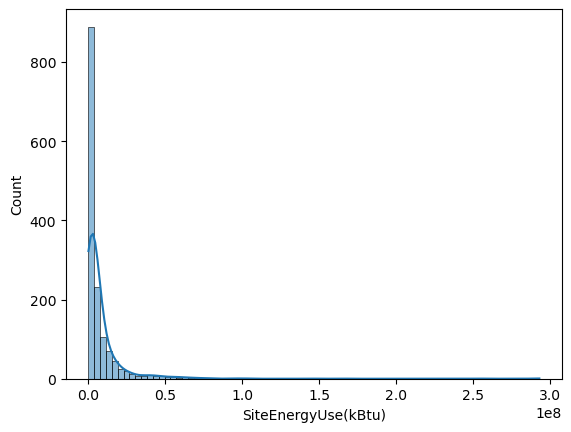

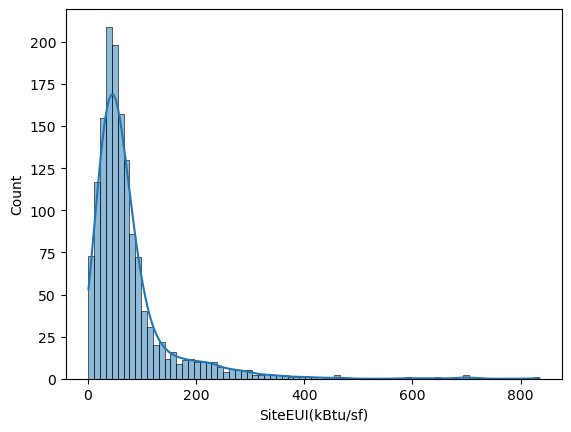

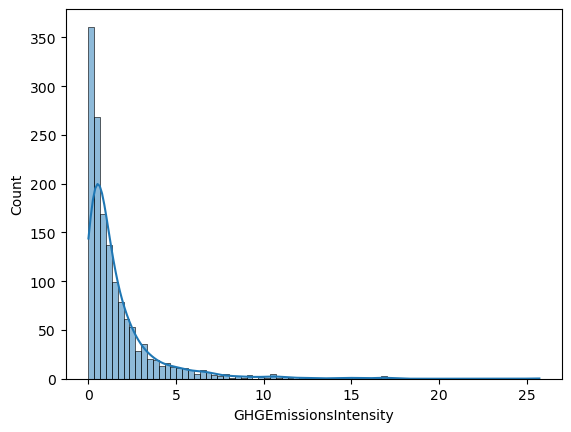

In [18]:
sns.histplot(df_model['SiteEnergyUse(kBtu)'], kde=True)
plt.show()
sns.histplot(df_model['SiteEUI(kBtu/sf)'], kde=True)       # Target Conso
plt.show()
sns.histplot(df_model['GHGEmissionsIntensity'], kde=True)  # Target Emissions
plt.show()

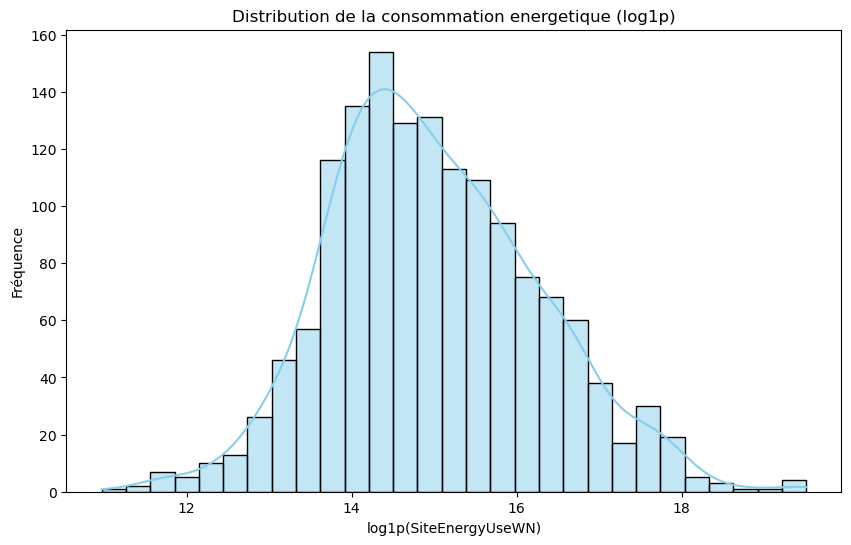

In [19]:
plt.figure(figsize=(10, 6))
sns.histplot(df_model['Log1p_SiteEnergyUseWN'], kde=True, color='skyblue')

plt.title('Distribution de la consommation energetique (log1p)')
plt.xlabel('log1p(SiteEnergyUseWN)')
plt.ylabel('Fréquence')
plt.show()

## Comparaison de différents modèles supervisés

A réaliser :
* Pour chaque algorithme que vous allez tester, vous devez :
    * Réaliser au préalable une séparation en jeu d'apprentissage et jeu de test via une validation croisée.
    * Si les features quantitatives que vous souhaitez utiliser ont des ordres de grandeur très différents les uns des autres, et que vous utilisez un algorithme de regression qui est sensible à cette différence, alors il faut réaliser un scaling (normalisation) de la donnée au préalable.
    * Entrainer le modèle sur le jeu de Train
    * Prédire la cible sur la donnée de test (nous appelons cette étape, l'inférence).
    * Calculer les métriques de performance R2, MAE et RMSE sur le jeu de train et de test.
    * Interpréter les résultats pour juger de la fiabilité de l'algorithme.
* Vous pouvez choisir par exemple de tester un modèle linéaire, un modèle à base d'arbres et un modèle de type SVM
* Déterminer le modèle le plus performant parmi ceux testés.

### >>> Models Testing & Scoring

#### Fonction models_testing_scoring()  v2

In [20]:
def models_testing_scoring2(titleinfo,Target2Log1p=False):
    lesmodels = {
        'LinearReg'        : LinearRegression(),
        'Ridge'            : Ridge(),
        'RandomForest'     : RandomForestRegressor(random_state=42),
        'GradientBoosting' : GradientBoostingRegressor(random_state=42),
        'XGBoost'          : XGBRegressor(random_state=42)
    }

    print("============================ " + datetime.now().strftime("%Y-%m-%d %H:%M:%S") + " =========================== "+titleinfo)     
    print()   
    print("Features     -ohe-     : "+str(ohe_features))
    print("          -robustscal- : "+str(robustscal_features))
    strfeat = str(donottouch_features)
    print("             -asis-    : " + (strfeat[:200] + '...' if len(strfeat) > 200 else strfeat))   
    print()
    if(Target2Log1p):
      print("Target (=> Log1p)      : "+latarget)
    else:
      print("Target                 : "+latarget)
    print()
    print(f"Nb lignes, X: {len(X)} | X_train: {len(X_train)} | X_test: {len(X_test)}")    
    print(f"Nb de colonnes, X : {X.shape[1]}")      
    print(flush=True)

    # Stratification sur la target réelle
    y_train_bins = pd.qcut(y_train, q=10, labels=False, duplicates='drop')  
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
 
    for name, lemodel in lesmodels.items():
        chronostart = time.time()
        
        if(Target2Log1p):
            themodel = TransformedTargetRegressor(regressor=lemodel, func=np.log1p, inverse_func=np.expm1)     # Target = log1p, true Target = expm1 
        else:    
            themodel = lemodel

        pipe = Pipeline(steps=[('preprocessor', lepreprocessor), ('model', themodel)])
        
        # Le y_train passé ici doit être la valeur RÉELLE
        cv_results = cross_validate(pipe, X_train, y_train, cv=skf.split(X_train, y_train_bins),
                                    scoring=['r2', 
                                            'neg_mean_absolute_error',
                                            'neg_root_mean_squared_error'])

        r2   = cv_results['test_r2'].mean()
        mae  = -cv_results['test_neg_mean_absolute_error'].mean()
        rmse = -cv_results['test_neg_root_mean_squared_error'].mean()
        print(f"{name:16} mean() | R²: {r2:.3f} | MAE: {mae:,.1f} | RMSE: {rmse:,.1f} |      Temps d'exec: {time.time() - chronostart:.1f}s")  

        for i in range(len(cv_results['test_r2'])):
            fold_r2   = cv_results['test_r2'][i]
            fold_mae  = -cv_results['test_neg_mean_absolute_error'][i]
            fold_rmse = -cv_results['test_neg_root_mean_squared_error'][i]
            print(f"                  fold{i+1} | R²: {fold_r2:.3f} | MAE: {fold_mae:,.1f} | RMSE: {fold_rmse:,.1f} |")

        # Entraînement final
        pipe.fit(X_train, y_train)
        y_pred = pipe.predict(X_test) # Sortie directe en unité réelle

        # Calcul final sur le test set (unité réelle)
        r2_test   = r2_score(y_test, y_pred)
        mae_test  = mean_absolute_error(y_test, y_pred)
        rmse_test = np.sqrt(mean_squared_error(y_test, y_pred))

        print(f"                   test | R²: {r2_test:.3f} | MAE: {mae_test:,.1f} | RMSE: {rmse_test:,.1f} |")
        print()

#### Old function models_testing_scoring (obsolete)

In [21]:
def models_testing_scoring(titleinfo):
    lesmodels = {
#       'Dummy'        : DummyRegressor(strategy='mean'),
#       'SVM'          : SVR(),
        'LinearReg'    : LinearRegression(),
        'Ridge'        : Ridge(),
#        'Lasso'        : Lasso(),
#        'ElasticNet'   : ElasticNet(),        
        'RandomForest' : RandomForestRegressor(random_state=42),
        'GradientBoosting' : GradientBoostingRegressor(random_state=42),
        'XGBoost': XGBRegressor(random_state=42)
    }

    print("============================ " + datetime.now().strftime("%Y-%m-%d %H:%M:%S") + " =========================== "+titleinfo)     
    print()   
    print("Features    -ohe-     : "+str(ohe_features))
    print("         -robustscal- : "+str(robustscal_features))
    strfeat = str(donottouch_features)
    print("            -asis-    : " + (strfeat[:200] + '...' if len(strfeat) > 200 else strfeat))   
    print()
    print("Target                : "+latarget)
    print()
    print(f"Nb lignes, X: {len(X)} | X_train: {len(X_train)} | X_test: {len(X_test)}")    
    print(flush=True)

    y_train_bins = pd.qcut(y_train, q=10, labels=False, duplicates='drop')   #augmenter le nbre de classes => q=10 ?
 
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
 
    for name, lemodel in lesmodels.items():
        chronostart = time.time()
        pipe = Pipeline(steps=[('preprocessor', lepreprocessor), ('model', lemodel)])
        cv_results = cross_validate(pipe, X_train, y_train, cv=skf.split(X_train, y_train_bins),                           # Cross validation (Train)
                                scoring=['neg_mean_absolute_percentage_error',
                                        'r2', 
                                        'neg_mean_absolute_error',
                                        'neg_root_mean_squared_error'])

        r2   = cv_results['test_r2'].mean()
        mae  = -cv_results['test_neg_mean_absolute_error'].mean()
        rmse = -cv_results['test_neg_root_mean_squared_error'].mean()
        print(f"{name:16} mean() | R²: {r2:.3f} | MAE: {mae:.1f} | RMSE: {rmse:.1f} |       Temps d'exec: {time.time() - chronostart:.1f}s")  

        for i in range(len(cv_results['test_r2'])):                                         # Train each fold scoring
            r2   = cv_results['test_r2'][i]
            mae  = -cv_results['test_neg_mean_absolute_error'][i]
            rmse = -cv_results['test_neg_root_mean_squared_error'][i]
            print(f"                  fold{i+1} | R²: {r2:.3f} | MAE: {mae:.1f} | RMSE: {rmse:.1f} |")

        chronostart = time.time()
        pipe.fit(X_train, y_train)                                                          # Test scoring
        y_pred = pipe.predict(X_test)

        for i in range(2 if "Log1p_" in latarget  else 1):
            # i=0 -> Log, i=1 -> Réel
            y_s_test = np.expm1(y_test) if i == 1 else y_test
            y_s_pred = np.expm1(y_pred) if i == 1 else y_pred
            label    = "test (expm1)" if i == 1 else "test        "

            r2   = r2_score(y_s_test, y_s_pred)
            mae  = mean_absolute_error(y_s_test, y_s_pred)
            rmse = np.sqrt(mean_squared_error(y_s_test, y_s_pred))

            print(f"           {label} | R²: {r2:.3f} | MAE: {mae:,.1f} | RMSE: {rmse:,.1f} |")
                    
        print()



#### Fonction add_weighted_ohe() ===> **wohe**

In [22]:
def add_weighted_ohe(thedf, thetypecol, theratiocol):
    dummies = pd.get_dummies(thedf[thetypecol], prefix="wohe_")
    dummies = dummies.mul(thedf[theratiocol], axis=0)
    
    existing = thedf.reindex(columns=dummies.columns, fill_value=0)

    thedf[dummies.columns] = existing.add(dummies, fill_value=0)

    return thedf

#### >>> Selections des Features et Target + X, y, splits, Columntransformer/Preprocessor et appel fct models_testing_scoring

In [34]:
#df_model2=df_model.copy()                                         # Sur tout le dataset (env 1500 lignes)
df_model2=df_model[df_model['ENERGYSTARScore']>0].copy()        # Solo le sous-ensemble ou ENERGYSTARSCore > 0  (env 950 lignes)

# La Target:
#latarget = 'SiteEnergyUse(kBtu)'          # Conso total
#latarget='Log1p_SiteEnergyUse'
#latarget='Log1p_SiteEnergyUseWN'
#latarget  = 'GHGEmissionsIntensity'   # Emissions/sf
 
#latarget = 'SiteEnergyUseWN(kBtu)'          # Conso total WN
latarget='TotalGHGEmissions'
latarget2log1p=True


# Les Features:                                      
ohe_features        = ['PeriodBuilt','Neighborhood'] #,'PrimaryPropertyType'] 
robustscal_features = ['Log1p_GFATotal',  'NumberofFloors', 'NumberofBuildings' 
                      ,'ENERGYSTARScore']
#donottouch_features  = ['Has_Electricity', 'Has_Gas', 'Has_Steam', 'Struct_ParkingRatio']    
donottouch_features  = ['Energy_ElecRatio', 'Energy_GasRatio', 'Energy_SteamRatio', 'Struct_ParkingRatio']

# + Les wohe Features (ohe pondérés):
df_model2 = add_weighted_ohe(df_model2, 'LargestPropertyUseType', 'Usage_1_Ratio')
df_model2 = add_weighted_ohe(df_model2, 'SecondLargestPropertyUseType', 'Usage_2_Ratio')
df_model2 = add_weighted_ohe(df_model2, 'ThirdLargestPropertyUseType', 'Usage_3_Ratio')
wohe_features=df_model2.filter(regex='^wohe_').columns.tolist()

donottouch_features = donottouch_features + wohe_features

lesfeatures = ohe_features + robustscal_features + donottouch_features

# X et y
X = df_model2[lesfeatures]
y = df_model2[latarget]
y_bins = pd.qcut(y, q=5, labels=False)  # quantiles → 5 classes

# Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42 , stratify=y_bins)
#X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42 , stratify=X['PeriodBuilt'])

# ColumnTransformer:
lestransformers = []

if ohe_features:
    lestransformers.append(('ohe', OneHotEncoder(max_categories=60, handle_unknown='infrequent_if_exist'), ohe_features))
if robustscal_features:
    lestransformers.append(('robustscal', RobustScaler(), robustscal_features))
if donottouch_features:
    lestransformers.append(('donttouch', 'passthrough', donottouch_features))

lepreprocessor = ColumnTransformer(transformers=lestransformers)

models_testing_scoring2(str(latarget)+' & log1p='+str(latarget2log1p), latarget2log1p)

#models_testing_scoring('Target as is + fonction initiale')


============================ 2026-04-22 13:20:48 =========================== TotalGHGEmissions & log1p=True

Features     -ohe-     : ['PeriodBuilt', 'Neighborhood']
          -robustscal- : ['Log1p_GFATotal', 'NumberofFloors', 'NumberofBuildings', 'ENERGYSTARScore']
             -asis-    : ['Energy_ElecRatio', 'Energy_GasRatio', 'Energy_SteamRatio', 'Struct_ParkingRatio', 'wohe__Bank Branch', 'wohe__Courthouse', 'wohe__Data Center', 'wohe__Distribution Center', 'wohe__Financial Office',...

Target (=> Log1p)      : TotalGHGEmissions

Nb lignes, X: 958 | X_train: 766 | X_test: 192
Nb de colonnes, X : 53

LinearReg        mean() | R²: 0.763 | MAE: 59.2 | RMSE: 291.2 |      Temps d'exec: 0.9s
                  fold1 | R²: 0.451 | MAE: 68.5 | RMSE: 412.6 |
                  fold2 | R²: 0.814 | MAE: 91.3 | RMSE: 449.8 |
                  fold3 | R²: 0.930 | MAE: 44.3 | RMSE: 230.4 |
                  fold4 | R²: 0.925 | MAE: 34.6 | RMSE: 84.8 |
                  fold5 | R²: 0.692 | MAE: 5

## Optimisation et interprétation du modèle

A réaliser :
* Reprennez le meilleur algorithme que vous avez sécurisé via l'étape précédente, et réalisez une GridSearch de petite taille sur au moins 3 hyperparamètres.
* Si le meilleur modèle fait partie de la famille des modèles à arbres (RandomForest, GradientBoosting) alors utilisez la fonctionnalité feature importance pour identifier les features les plus impactantes sur la performance du modèle. Sinon, utilisez la méthode Permutation Importance de sklearn.

### Gridsearch

#### Fonction gridsearch_model()   - old function - obsolete

In [24]:
# Fonction gridsearch_model()

def gridsearch_model(lemodel, param_grid, titleinfo):
    
    print("============================ " + datetime.now().strftime("%Y-%m-%d %H:%M:%S") + " =========================== "+titleinfo)     
    print()
    print('param_grid = '+ str(param_grid))
    print()    
    pipe = Pipeline(steps=[('preprocessor', lepreprocessor), ('model', lemodel)])

    y_train_bins = pd.qcut(y_train, q=10, labels=False, duplicates='drop')
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    
    grid_search = GridSearchCV(pipe, param_grid, cv=skf.split(X_train, y_train_bins), scoring=['r2', 'neg_mean_absolute_error', 'neg_root_mean_squared_error'],refit='r2')
    grid_search.fit(X_train, y_train)
  
    print("Meilleurs params:", grid_search.best_params_)
    idx = grid_search.best_index_
    mae  = -grid_search.cv_results_['mean_test_neg_mean_absolute_error'][idx]   # test mean_train_neg_mean_absolute_error
    rmse = -grid_search.cv_results_['mean_test_neg_root_mean_squared_error'][idx]
    print(f"Meilleur R² gscv: {grid_search.best_score_:.3f} | MAE: {mae:.1f} | RMSE: {rmse:.1f}")
    print()

    print('Best features (25):')
    print()
    feature_names = grid_search.best_estimator_.named_steps['preprocessor'].get_feature_names_out()
    importances = grid_search.best_estimator_.named_steps['model'].feature_importances_
    indices = np.argsort(importances)[::-1][:25]
    for i in indices:   print(f"     {feature_names[i]:55} | {importances[i]:.3f}")
    print('     ...')
    print()
    return grid_search

#### Fonction gridsearch_model2() - nouvelle fonction pour gerer les target log1p 

In [29]:
def gridsearch_model2(lemodel, param_grid, titleinfo, Target2Log1p=False):
    
    print("============================ " + datetime.now().strftime("%Y-%m-%d %H:%M:%S") + " =========================== "+titleinfo)     
    print()
    print('param_grid = '+ str(param_grid))
    print('Target Log-Transform : = '+ str(Target2Log1p))
    print(flush=True)   

    if(Target2Log1p):
        themodel = TransformedTargetRegressor(
            regressor=lemodel, 
            func=np.log1p, 
            inverse_func=np.expm1
        )
        new_param_grid = {f'model__regressor__{k}': v for k, v in param_grid.items()}
    else:
        themodel=lemodel
        new_param_grid = {f'model__{k}': v for k, v in param_grid.items()}

    pipe = Pipeline(steps=[('preprocessor', lepreprocessor), ('model', themodel)])

    y_train_bins = pd.qcut(y_train, q=10, labels=False, duplicates='drop')
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    
    # Le scoring se fera automatiquement sur les valeurs réelles (expm1)
    grid_search = GridSearchCV(
        pipe, 
        new_param_grid, 
        cv=skf.split(X_train, y_train_bins), 
        scoring=['r2', 'neg_mean_absolute_error', 'neg_root_mean_squared_error'],
        refit='r2',
        n_jobs=-1 # Pour aller plus vite
    )
    
    grid_search.fit(X_train, y_train)
  
    print("Meilleurs params:", grid_search.best_params_)
    idx = grid_search.best_index_
    
    # Les scores sont déjà désaisonnalisés du log par le wrapper
    mae  = -grid_search.cv_results_['mean_test_neg_mean_absolute_error'][idx]
    rmse = -grid_search.cv_results_['mean_test_neg_root_mean_squared_error'][idx]
    print(f"Meilleur R² gscv: {grid_search.best_score_:.3f} | MAE: {mae:,.1f} | RMSE: {rmse:,.1f}")
    print()

    print('Best features (25):')
    print()
    
    # Récupération des importances (il faut descendre dans model.regressor_)
    feature_names = grid_search.best_estimator_.named_steps['preprocessor'].get_feature_names_out()
    if(Target2Log1p):
        importances = grid_search.best_estimator_.named_steps['model'].regressor_.feature_importances_
    else:
        importances = grid_search.best_estimator_.named_steps['model'].feature_importances_

    indices = np.argsort(importances)[::-1][:25]
    for i in indices: print(f"     {feature_names[i]:55} | {importances[i]:.3f}")
    
    print('     ...')
    print()
    return grid_search

#### >>> gridsearch execution

In [35]:
# gridsearch execution 

thechoice = 'XGBoost'              # Choix du modele

models_config = {
    'RandomForest': {
        'model': RandomForestRegressor(n_jobs=-1, random_state=42),
        'title': "RandomForest GridSearch",
        'params': {
            'n_estimators': [ 300, 350, 400, 500, 600],
            'max_depth': [8, 10, 12, 15], # pas bon trop de depth ()
            'min_samples_split': [2],  #, 4],
            'max_features': ['sqrt', 'log2']
        }
    },  
    'GradientBoost': {
        'model': GradientBoostingRegressor(random_state=42),
        'title': "GradientBoost GridSearch",
        'params': {
            'n_estimators': [250, 300, 350, 400],
            'max_depth': [3, 4, 5, 7],
            'learning_rate': [0.05, 0.1, 0.2],
            'subsample': [0.8, 1.0]
        }
    },
    'XGBoost': {
        'model': XGBRegressor(random_state=42, n_jobs=-1),
        'title': "XGBoost GridSearch",
        'params': {
            'n_estimators':     [200, 300, 400],
            'learning_rate':    [0.05, 0.1, 0.2],
            'max_depth':        [3, 4, 6],
            'subsample':        [0.8, 1.0],
            'colsample_bytree': [0.8, 1.0]
        }
    },
    'XGBoost2': {
        'model': XGBRegressor(random_state=42, n_jobs=-1),
        'title': "XGBoost2 GridSearch",
        'params': {
            'n_estimators':     [200],
            'learning_rate':    [0.1],
            'max_depth':        [4],
            'subsample':        [0.8],
            'colsample_bytree': [1.0]
        }
    }
}

config = models_config.get(thechoice)

if config is None:
    print(f"Modèle inconnu: {thechoice}")
else:
    gs = gridsearch_model2(config['model'], config['params'], config['title'],latarget2log1p) 

# ========== gs.best_estimator score on test
y_pred = gs.best_estimator_.predict(X_test)

r2   = r2_score(y_test, y_pred)
mae  = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print(f"         test dataset | R²: {r2:.3f} | MAE: {mae:,.1f} | RMSE: {rmse:,.1f} |")
print()


============================ 2026-04-22 13:22:43 =========================== XGBoost GridSearch

param_grid = {'n_estimators': [200, 300, 400], 'learning_rate': [0.05, 0.1, 0.2], 'max_depth': [3, 4, 6], 'subsample': [0.8, 1.0], 'colsample_bytree': [0.8, 1.0]}
Target Log-Transform : = True

Meilleurs params: {'model__regressor__colsample_bytree': 0.8, 'model__regressor__learning_rate': 0.2, 'model__regressor__max_depth': 4, 'model__regressor__n_estimators': 200, 'model__regressor__subsample': 1.0}
Meilleur R² gscv: 0.798 | MAE: 58.4 | RMSE: 240.5

Best features (25):

     donttouch__Energy_ElecRatio                             | 0.181
     robustscal__Log1p_GFATotal                              | 0.131
     donttouch__wohe__Hospital (General Medical & Surgical)  | 0.113
     donttouch__wohe__Supermarket/Grocery Store              | 0.109
     robustscal__NumberofFloors                              | 0.078
     donttouch__wohe__Non-Refrigerated Warehouse             | 0.055
     donttou

## SHAP (méthode d'interprétabilité basée sur la contribution individuelle des variables à la prédiction)

### Shap summary plot - features importances globale - 

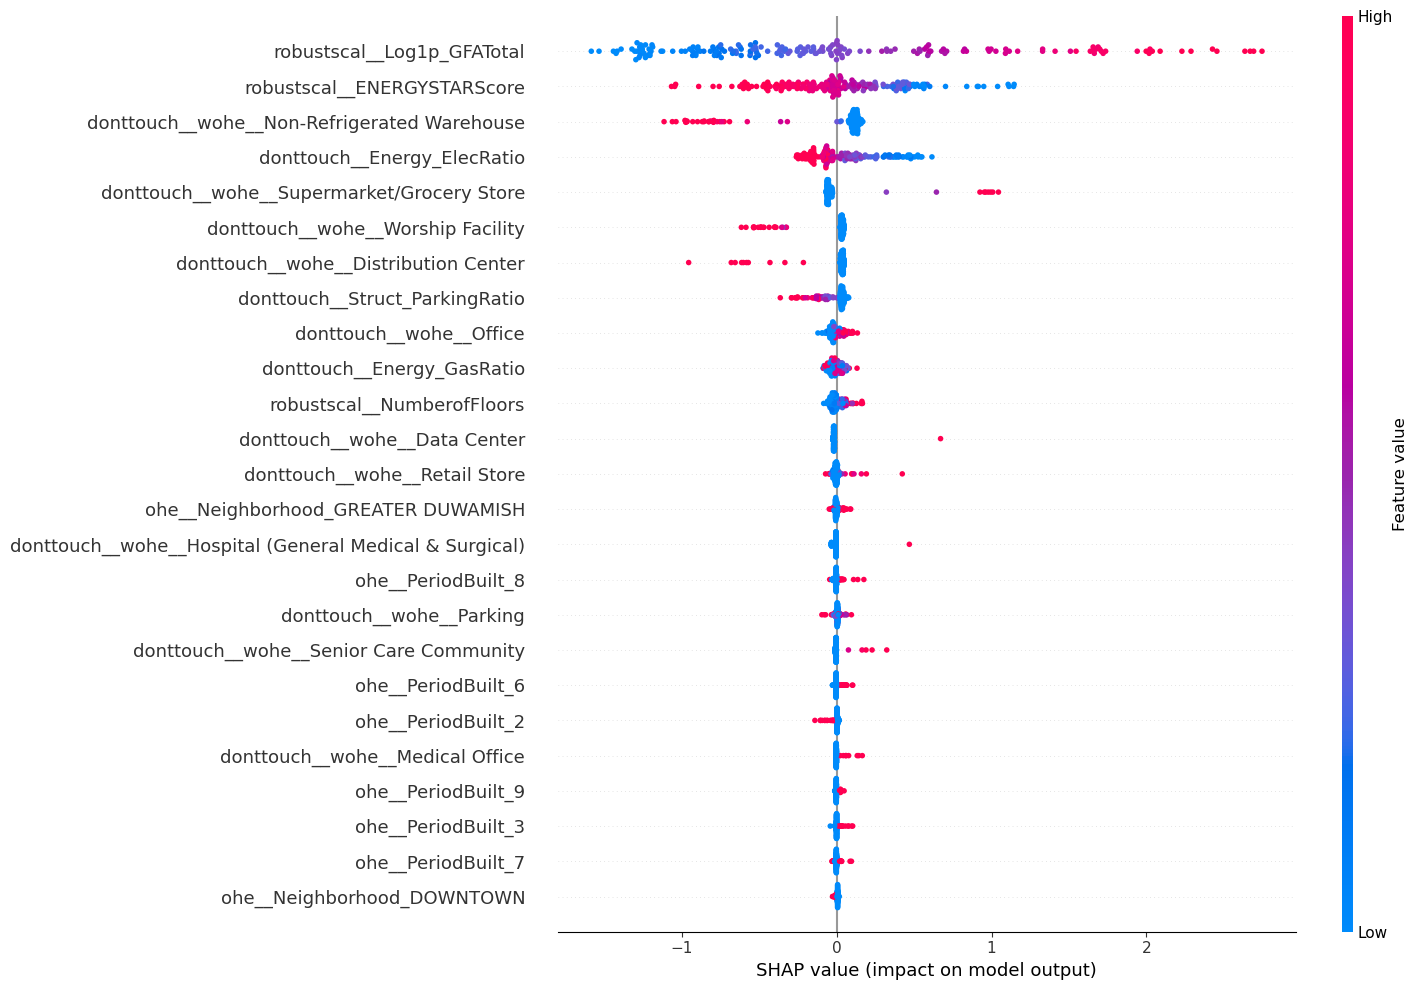

In [33]:
model_final = gs.best_estimator_.named_steps['model']
if hasattr(model_final, 'regressor_'):
    model_final = model_final.regressor_

X_test_trans = gs.best_estimator_.named_steps['preprocessor'].transform(X_test)
feature_names = gs.best_estimator_.named_steps['preprocessor'].get_feature_names_out()

explainer = shap.TreeExplainer(model_final)    # Calcul du shap
shap_values = explainer.shap_values(X_test_trans)

shap.summary_plot(shap_values, X_test_trans, feature_names=feature_names, plot_size=(15, 10),max_display=25)

### Shap waterfall plot - feature importances locale - 

##### la fonction shapfall(idx,title)  => shap.plot.waterfall

In [83]:
def shapfall(idx, title):
    shap.plots.waterfall(shap.Explanation(values=shap_values[idx], 
                                        base_values=explainer.expected_value,
                                        data=X_test_trans[idx],
                                        feature_names=feature_names),
                        show=False)
    plt.gcf().set_size_inches(12, 7)
    plt.title(title, fontsize=16, fontweight='bold',  y=0.94, x=0.5, transform=plt.gcf().transFigure)
    plt.tight_layout()
    plt.show()

##### quelques SHAP waterfalls

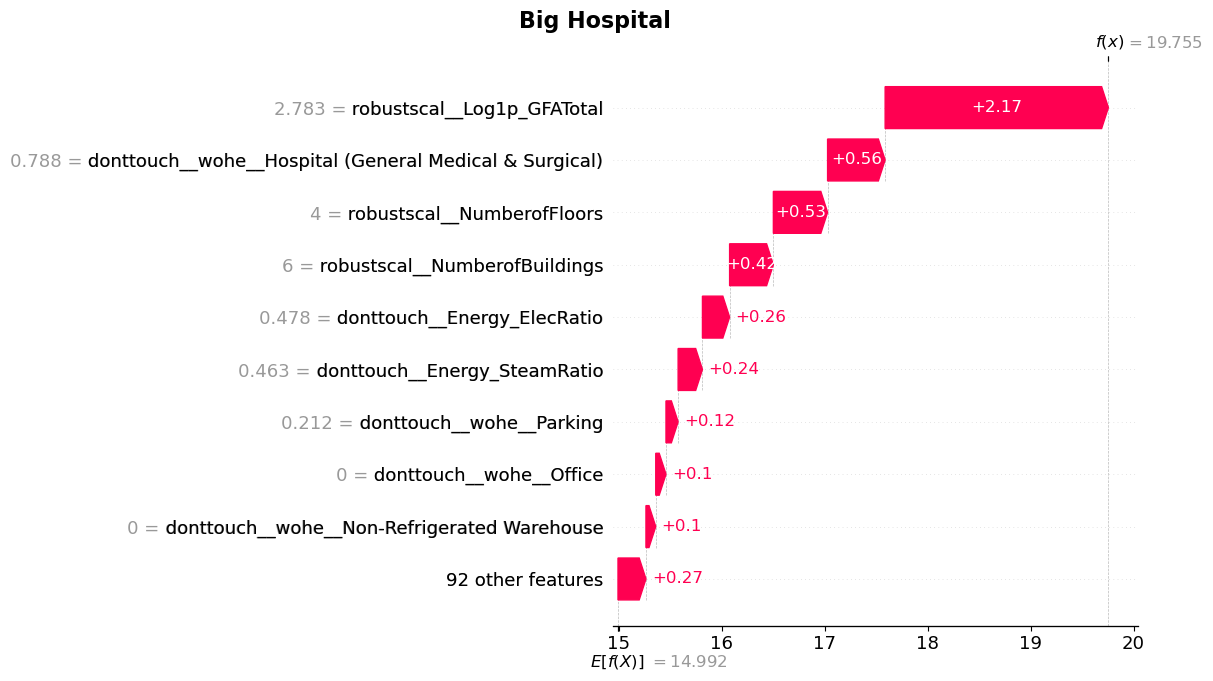

In [84]:
shapfall(169,"Big Hospital")

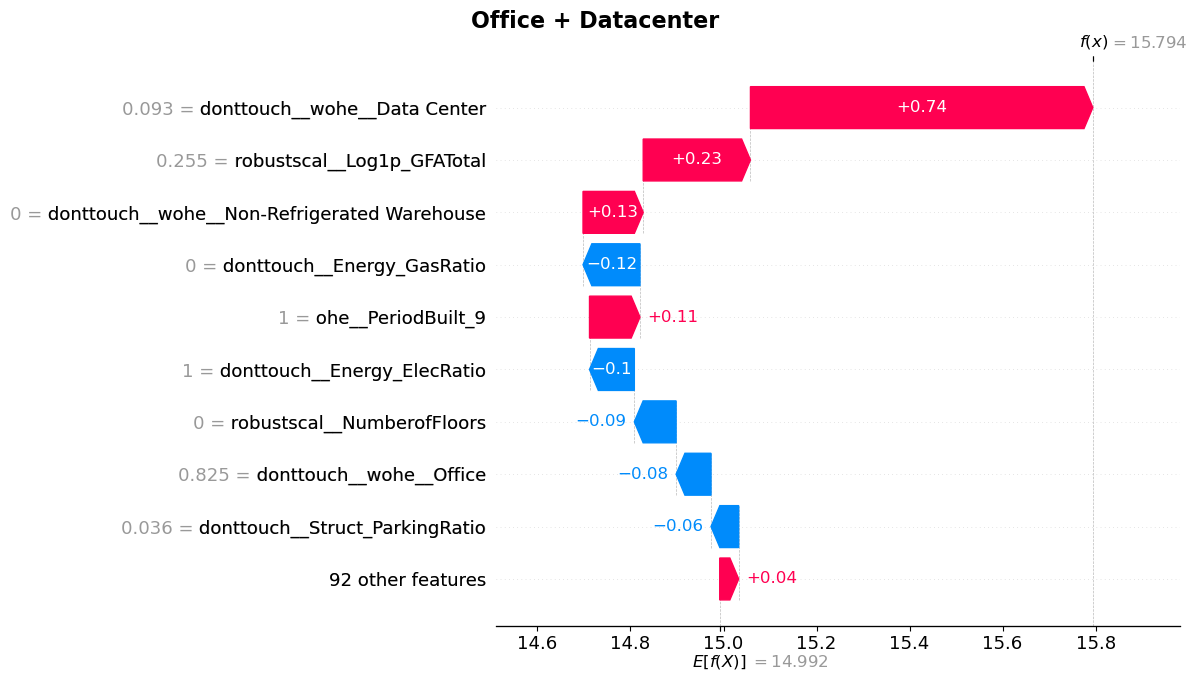

In [85]:
shapfall(39,"Office + Datacenter")

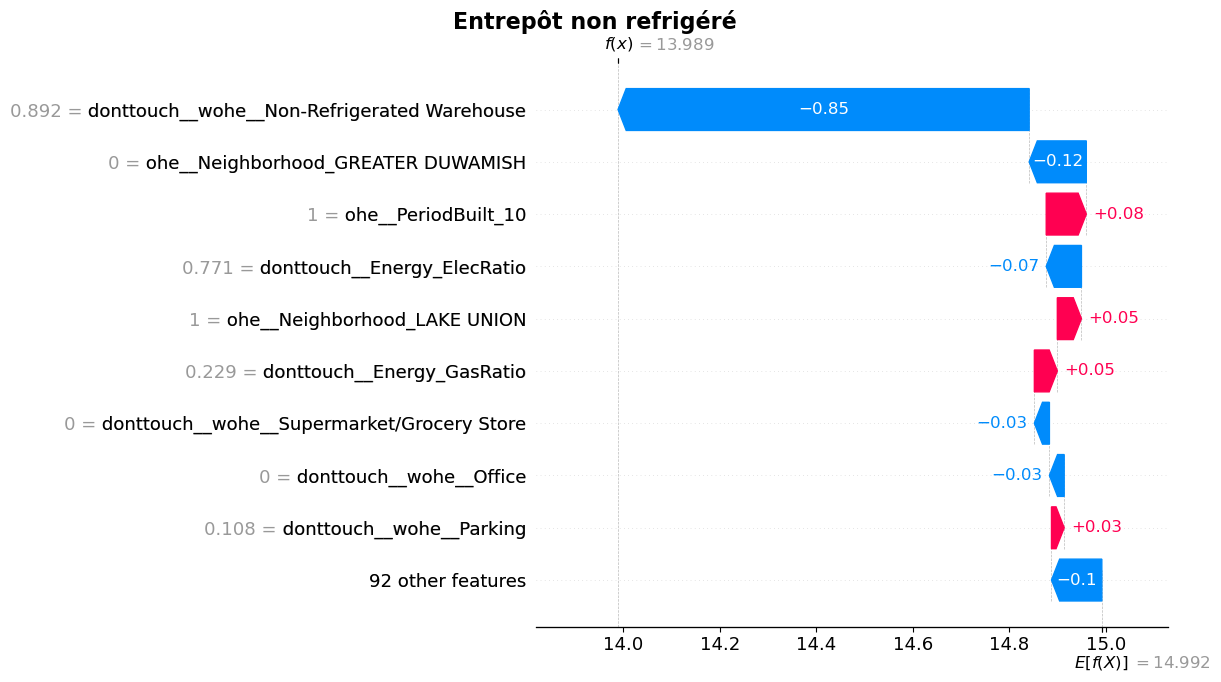

In [87]:
shapfall(13,"Entrepôt non refrigéré")